# 01 Explore: CFPB complaints, Jan-Feb 2025

**Goal of this notebook:** look at the raw data before changing anything. No cleaning here, only counting and reading.

**Data:** `data/raw/CCDB_Export_9_January_2025_through_February_2025.zip`, from the CFPB Consumer Complaint Database Narratives Archive (FOIA reading room). The live CFPB database removed narratives in Sept 2026, so this archive is the only source.

Questions this notebook answers:
1. What columns are there, and how are missing values coded?
2. What date range, and how many complaints per month?
3. What share of complaints have a narrative (the customer's own text)?
4. How many narratives are exact duplicates?
5. How are complaints spread across products (our label)?
6. How long are narratives?
7. What does the redaction (`XXXX`) look like?

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Find the project root by walking up until we see README.md.
# This works whether the notebook runs from notebooks/ or from the project folder.
ROOT = Path.cwd()
while not (ROOT / "README.md").exists():
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw" / "CCDB_Export_9_January_2025_through_February_2025.zip"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

print(pd.__version__)
print(RAW.exists(), RAW.stat().st_size / 1e6, "MB")

3.1.0
True 75.475199 MB


## 1. Columns

The CSV inside the zip is about 490 MB. Before loading all of it, read only the first 5 rows to see the column names.
pandas can read a `.zip` directly when it holds a single CSV, so we never unzip (the raw file stays untouched).

In [2]:
peek = pd.read_csv(RAW, nrows=5, dtype=str)
print(len(peek.columns), "columns")
peek.T

16 columns


,0,1,2,3,4
Date received,2025-01-04,2025-01-04,2025-01-04,2025-01-25,2025-01-25
Product,Credit reporting or other personal consumer re...,Credit reporting or other personal consumer re...,Credit reporting or other personal consumer re...,Credit reporting or other personal consumer re...,Credit reporting or other personal consumer re...
Sub-product,Credit reporting,Credit reporting,Credit reporting,Credit reporting,Credit reporting
Issue,Incorrect information on your report,Incorrect information on your report,Incorrect information on your report,Incorrect information on your report,Incorrect information on your report
Sub-issue,Information belongs to someone else,Information belongs to someone else,Information belongs to someone else,Information belongs to someone else,Information belongs to someone else
Consumer complaint narrative,NaN,NaN,NaN,NaN,NaN
Company public response,Company has responded to the consumer and the ...,NaN,Company has responded to the consumer and the ...,Company has responded to the consumer and the ...,Company has responded to the consumer and the ...
Company,Experian Information Solutions Inc.,"EQUIFAX, INC.","TRANSUNION INTERMEDIATE HOLDINGS, INC.","TRANSUNION INTERMEDIATE HOLDINGS, INC.",Experian Information Solutions Inc.
State,PR,PR,PR,FL,FL
ZIP code,00949,00949,00949,34744,34744


## 2. Load the columns we need

Three choices, each on purpose:
- `usecols`: we only need 7 of the 16 columns. Fewer columns means less memory.
- `dtype=str`: read everything as text. `Complaint ID` is a label, not a number (lesson from Project 1), and dates we parse ourselves.
- `keep_default_na=False`: by default pandas turns strings like `"NA"`, `"None"` or `"null"` into missing values. In free text that would be wrong (lesson from Project 2). With this, an empty cell stays an empty string `""`, and we decide what counts as missing.

In [3]:
COLS = ["Date received", "Product", "Sub-product", "Issue",
        "Consumer complaint narrative", "Company", "Complaint ID"]

df = pd.read_csv(RAW, usecols=COLS, dtype=str, keep_default_na=False)
print(df.shape)
print(round(df.memory_usage(deep=True).sum() / 1e9, 2), "GB in memory")
df.dtypes

(811019, 7)
0.64 GB in memory


Date received                   str
Product                         str
Sub-product                     str
Issue                           str
Consumer complaint narrative    str
Company                         str
Complaint ID                    str
dtype: object

In [4]:
# How many cells are empty strings, per column?
(df == "").sum().sort_values(ascending=False)

Consumer complaint narrative    545614
Product                              0
Date received                        0
Sub-product                          0
Issue                                0
Company                              0
Complaint ID                         0
dtype: int64

In [5]:
# Is Complaint ID unique? It should be: one row per complaint.
print("rows:", len(df), "| unique IDs:", df["Complaint ID"].nunique())

rows: 811019 | unique IDs: 811019


## 3. Dates

In [6]:
df["Date received"] = pd.to_datetime(df["Date received"], format="%Y-%m-%d")
print(df["Date received"].min(), "->", df["Date received"].max())
df["month"] = df["Date received"].dt.to_period("M")
df["month"].value_counts().sort_index()

2025-01-01 00:00:00 -> 2025-02-28 00:00:00


month
2025-01    475783
2025-02    335236
Freq: M, Name: count, dtype: int64

## 4. Share with a narrative

A narrative is only published when the consumer agreed to share it, so most complaints have none. `.str.strip()` removes spaces first, so a narrative that is only whitespace also counts as empty.

In [7]:
df["has_narrative"] = df["Consumer complaint narrative"].str.strip() != ""

print("with narrative:", df["has_narrative"].sum(), f"({df['has_narrative'].mean():.1%})")

# Per month: count of rows, and how many have a narrative.
# The mean of a True/False column is the share of True.
df.groupby("month")["has_narrative"].agg(rows="size", with_narrative="sum", share="mean")

with narrative: 265405 (32.7%)


,rows,with_narrative,share
month,,,
2025-01,475783,172937,0.363479
2025-02,335236,92468,0.275830


## 5. Duplicate narratives

From here on we only look at rows with a narrative. If the same text appears many times (for example a template many people copy-paste), it can end up in both train and test. Then the model just memorises it and the test score looks better than it really is.

In [8]:
nar = df[df["has_narrative"]].copy()
text = nar["Consumer complaint narrative"]

counts = text.value_counts()          # each distinct text -> how many rows have it
repeated = counts[counts > 1]

print("rows with narrative:     ", len(nar))
print("distinct narrative texts:", text.nunique())
print("texts that repeat:       ", len(repeated), "covering", repeated.sum(), "rows")

rows with narrative:      265405
distinct narrative texts: 147596
texts that repeat:        18853 covering 136662 rows


In [9]:
# The 5 most repeated texts: how often, which product(s) and company, and the start of the text.
top = repeated.head(5).index
(nar[text.isin(top)]
   .groupby("Consumer complaint narrative")
   .agg(times=("Complaint ID", "size"),
        products=("Product", "nunique"),
        top_product=("Product", lambda s: s.mode()[0]),
        top_company=("Company", lambda s: s.mode()[0]))
   .sort_values("times", ascending=False)
   .rename(index=lambda t: t[:90] + "...")
)

,times,products,top_product,top_company
Consumer complaint narrative,,,,
"I am filing a complaint against Cash App ( Block , Inc. ) due to inadequate customer servi...",7410,3,"Money transfer, virtual currency, or money ser...","Block, Inc."
"I am writing to formally express my concerns regarding Zelle 's handling of disputes, part...",3594,3,"Money transfer, virtual currency, or money ser...","Early Warning Services, LLC"
I AM SUBMITTING THIS WITHOUT ANY INFLUENCE AND THIS IS NOT A THIRD PARTY. THE CREDIT BUREA...,3149,1,Credit reporting or other personal consumer re...,"EQUIFAX, INC."
My credit reports are inaccurate. These inaccuracies are causing creditors to deny me cred...,2446,1,Credit reporting or other personal consumer re...,"TRANSUNION INTERMEDIATE HOLDINGS, INC."
I am writing to file a complaint against Navy Federal Credit Union regarding multiple over...,2380,2,Checking or savings account,NAVY FEDERAL CREDIT UNION


## 6. Products (the label we will predict)

Two counts per product: all rows with a narrative, and distinct texts only (what is left after exact dedupe, which we do in notebook 02).

In [10]:
by_product = pd.DataFrame({
    "with_narrative": nar["Product"].value_counts(),
    "distinct_texts": nar.drop_duplicates("Consumer complaint narrative")["Product"].value_counts(),
})
by_product["share_distinct"] = (by_product["distinct_texts"] / by_product["distinct_texts"].sum()).round(3)
by_product.sort_values("distinct_texts", ascending=False)

,with_narrative,distinct_texts,share_distinct
Product,,,
Credit reporting or other personal consumer reports,170863,82984,0.562
"Money transfer, virtual currency, or money service",46258,23237,0.157
Checking or savings account,17070,13074,0.089
Debt collection,15288,12915,0.088
Credit card,6958,6452,0.044
Mortgage,2330,2330,0.016
Student loan,2201,2185,0.015
Vehicle loan or lease,1910,1901,0.013
"Payday loan, title loan, personal loan, or advance loan",1121,1114,0.008


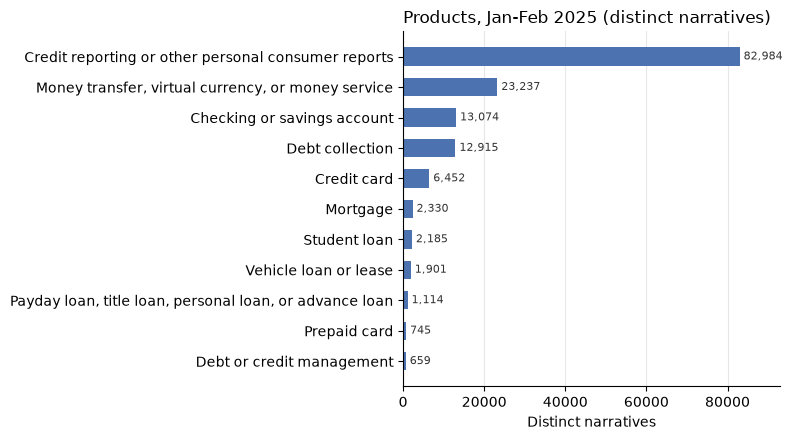

In [11]:
s = by_product["distinct_texts"].sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(s.index, s.values, color="#4C72B0", height=0.6)
for y, v in enumerate(s.values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8, color="#333333")
ax.set_xlim(0, s.max() * 1.12)   # room for the value labels
ax.set_xlabel("Distinct narratives")
ax.set_title("Products, Jan-Feb 2025 (distinct narratives)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG / "01_product_distribution.png", dpi=150)
plt.show()

## 7. Narrative length

Length in words (split on whitespace). The median is more useful than the mean here, because a few very long complaints pull the mean up.

These counts are BEFORE dedupe. When you look at the histogram, watch for narrow spikes: a spike at one exact length usually means many copies of the same text.

In [12]:
nar["n_words"] = text.str.split().str.len()
nar["n_words"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(0)

count    265405.0
mean        152.0
std         178.0
min           1.0
10%          33.0
50%         102.0
90%         318.0
99%         803.0
max        6469.0
Name: n_words, dtype: float64

In [13]:
# Median length per product: do some products get longer complaints?
nar.groupby("Product")["n_words"].median().sort_values(ascending=False)

Product
Mortgage                                                   209.5
Student loan                                               168.0
Vehicle loan or lease                                      157.0
Credit card                                                139.5
Payday loan, title loan, personal loan, or advance loan    136.0
Prepaid card                                               110.0
Debt collection                                            107.0
Credit reporting or other personal consumer reports        104.0
Money transfer, virtual currency, or money service         102.0
Checking or savings account                                 77.0
Debt or credit management                                   64.0
Name: n_words, dtype: float64

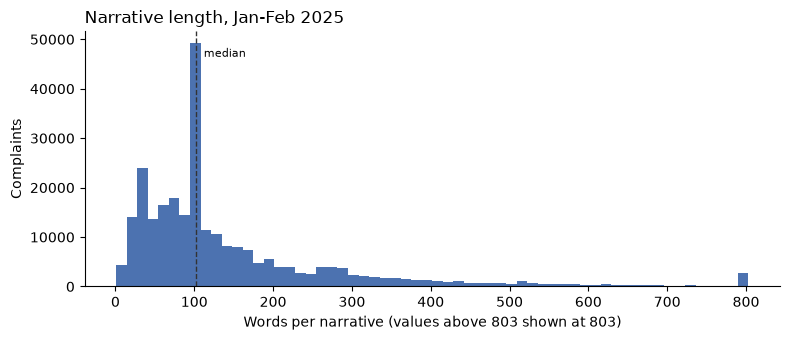

In [14]:
cap = int(nar["n_words"].quantile(0.99))   # cut the x-axis at the 99th percentile so the plot is readable

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(nar["n_words"].clip(upper=cap), bins=60, color="#4C72B0")
ax.axvline(nar["n_words"].median(), color="#333333", lw=1, ls="--")
ax.text(nar["n_words"].median(), ax.get_ylim()[1] * 0.9, "  median", fontsize=8)
ax.set_xlabel(f"Words per narrative (values above {cap} shown at {cap})")
ax.set_ylabel("Complaints")
ax.set_title("Narrative length, Jan-Feb 2025", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "01_narrative_length.png", dpi=150)
plt.show()

## 8. Redaction

The CFPB hides personal details (names, account numbers, dates) by replacing them with `X`s. Let's see which forms this takes, so notebook 02 can remove them properly.

The regex `\S*XX\S*` means: any run of non-space characters that contains `XX`.

In [15]:
has_xxxx = text.str.contains("XXXX")
print(f"narratives containing XXXX: {has_xxxx.mean():.1%}")

# The most common redacted tokens, e.g. 'XXXX', 'XX/XX/XXXX'
tokens = text.str.findall(r"\S*XX\S*").explode()
tokens.value_counts().head(15)

narratives containing XXXX: 50.3%


Consumer complaint narrative
XXXX               2317342
XX/XX/XXXX           97388
XXXX,                95529
XXXX.                73501
XXXXXXXX             52479
XX/XX/XXXX,          25070
XX/XX/year>          20268
XX/XX/XXXX.          13512
XX/XX/year>,          7117
XXXXXX/XX/XXXX        6583
XX/XX/year>.          4757
XX/XX/XXXXXXXX        4341
XXXXXXXX,             1961
XXXXXX/XX/year>       1948
XXXXXXXX.             1191
Name: count, dtype: int64

In [16]:
# Money amounts are kept but wrapped in braces, like {$500.00}. How common is that?
print(f"narratives with a {{$...}} amount: {text.str.contains(r'\{\$', regex=True).mean():.1%}")

narratives with a {$...} amount: 13.5%


## 9. Read a few

Numbers only tell part of the story. Read these and note anything surprising.

In [17]:
for _, row in nar.sample(3, random_state=42).iterrows():
    print(row["Product"], "|", row["Issue"])
    print(row["Consumer complaint narrative"][:600])
    print("-" * 80)

Credit reporting or other personal consumer reports | Incorrect information on your report
First of all, I don't know XXXX. I used translation software. Please forgive me if the translation is difficult to understand. In XX/XX/XXXX, I needed money and wanted to cash out a credit card. The staff of XXXX XXXX XXXXXXXX told me that my credit score was too low and I couldn't cash out a credit card. At that time, I began to doubt it because my score was XXXX when I did a credit cash out before. So I began to suspect that my credit was stolen, so I logged into XXXX to check my credit report and found that my credit score was only XXXX, so I called up the credit report. I received the cred
--------------------------------------------------------------------------------
Credit reporting or other personal consumer reports | Improper use of your report
Finding unauthorized accounts, credit inquiries, and false personal information made or reported without my knowledge or agreement completely stu